# Prueba individual · Sesión 03
### Career Tech Hub · Un caso de datos de principio a fin

**Nombre:** *Taisiia Horobets (19/11/2026)*

Trabajas con los mismos datos de la sesión. Lee antes el PDF de la prueba: ahí están las instrucciones y la rúbrica.

- Haz **al menos dos** de las partes A (pandas), B (SQL) y C (Excel o Power BI).
- La **parte D es obligatoria**.
- Este cuaderno tiene que estar en la misma carpeta que el cuaderno de la sesión, junto a la carpeta `datos`.

In [16]:
import sqlite3
import pandas as pd
import matplotlib.pyplot as plt
import numpy as np

# Las hojas del Excel (para la parte A)
dias = pd.read_excel("D:/prueba técnica TechHUB/datos/electricidad_para_panel.xlsx", sheet_name="dias")
generacion = pd.read_excel("D:/prueba técnica TechHUB/datos/electricidad_para_panel.xlsx", sheet_name="generacion")
dias_sequrity_copy = dias.copy()

# La base de datos (para la parte B)
conexion = sqlite3.connect("D:/prueba técnica TechHUB/datos/electricidad.db")

def sql(consulta):
    # Lanza una consulta y devuelve el resultado como tabla de pandas.
    return pd.read_sql(consulta, conexion)

print("Hoja dias:", dias.shape[0], "filas ·", list(dias.columns))
sql("SELECT type AS tipo, name AS nombre FROM sqlite_master WHERE type IN ('table', 'view') ORDER BY type, name")

Hoja dias: 1415 filas · ['fecha', 'dia_semana', 'mes', 'festivo', 'descanso', 't_med', 'demanda_gwh', 'año']


,tipo,nombre
0,table,ciudades
1,table,demanda
2,table,festivos
3,table,generacion
4,table,predicciones
5,table,tiempo
6,view,tabla_dias
7,view,temperatura_nacional


Columnas de las tablas de la base de datos:

| Tabla | Columnas |
|---|---|
| `demanda` | `fecha`, `demanda_gwh` |
| `generacion` | `fecha`, `tecnologia`, `tipo`, `gwh` |
| `tiempo` | `fecha`, `ciudad`, `t_max`, `t_min`, `t_med`, `lluvia_mm`, `viento_kmh`, `sol_mj` |
| `ciudades` | `ciudad`, `latitud`, `longitud`, `habitantes` |
| `festivos` | `fecha`, `festivo` |
| `temperatura_nacional` (vista) | `fecha`, `t_med` |
| `tabla_dias` (vista) | `fecha`, `demanda_gwh`, `t_med`, `festivo`, `demanda_ayer`, `demanda_hace_7` |

# Parte A · pandas

Usa la tabla `dias`.

**A1.** ¿Cuántos días superaron los 800 GWh de demanda? ¿Cuántos fueron en cada año?

In [17]:
dias_800gwh =(dias["demanda_gwh"] > 800).sum()

resultado1 = (dias[dias["demanda_gwh"] > 800].groupby("año").size().reset_index(name="num_excedencias"))
resultado1

,año,num_excedencias
0,2023,16
1,2024,10
2,2025,25
3,2026,64


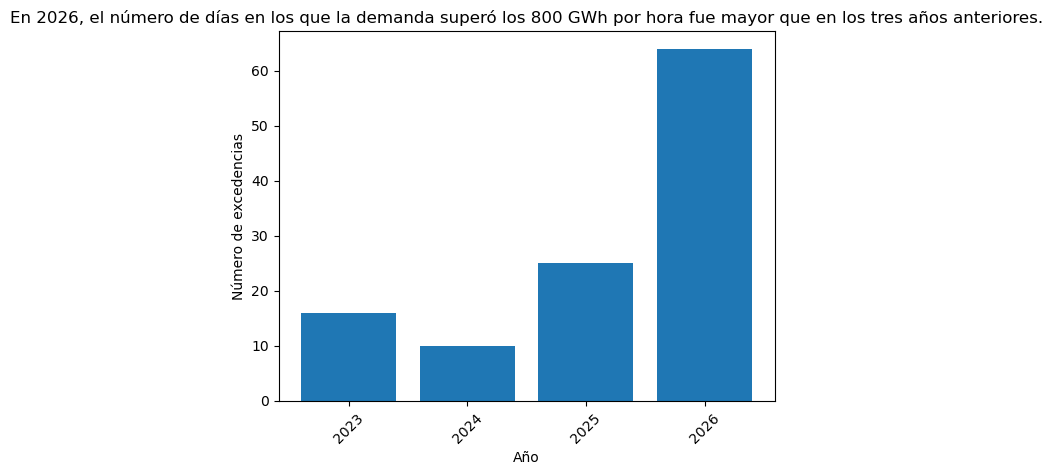

In [18]:
plt.bar(resultado1['año'], resultado1['num_excedencias'])
plt.title('En 2026, el número de días en los que la demanda superó los 800 GWh por hora fue mayor que en los tres años anteriores.')
plt.xlabel('Año')
plt.ylabel('Número de excedencias')

plt.xticks(resultado1['año'], rotation=45)
plt.show()


**A2.** Haz una tabla con la demanda media de cada año, separando los días laborables de los días de descanso (columna `descanso`). ¿Qué porcentaje menos se gasta en un día de descanso, cada año?

In [19]:
d_media_every_year = dias.groupby(["año", "descanso"])["demanda_gwh"].mean().round(2).unstack()
d_media_every_year = d_media_every_year.reset_index()
d_media_every_year.columns = ["año", "dia_laboral", "dia_de_descanso"]
d_media_every_year["pje_de_diferencia"] = ((d_media_every_year["dia_laboral"] - d_media_every_year["dia_de_descanso"]) / d_media_every_year["dia_laboral"] * 100).round(2)

d_media_every_year


,año,dia_laboral,dia_de_descanso,pje_de_diferencia
0,2023,707.72,605.50,14.44
1,2024,710.06,612.02,13.81
2,2025,732.49,633.23,13.55
3,2026,749.86,643.03,14.25


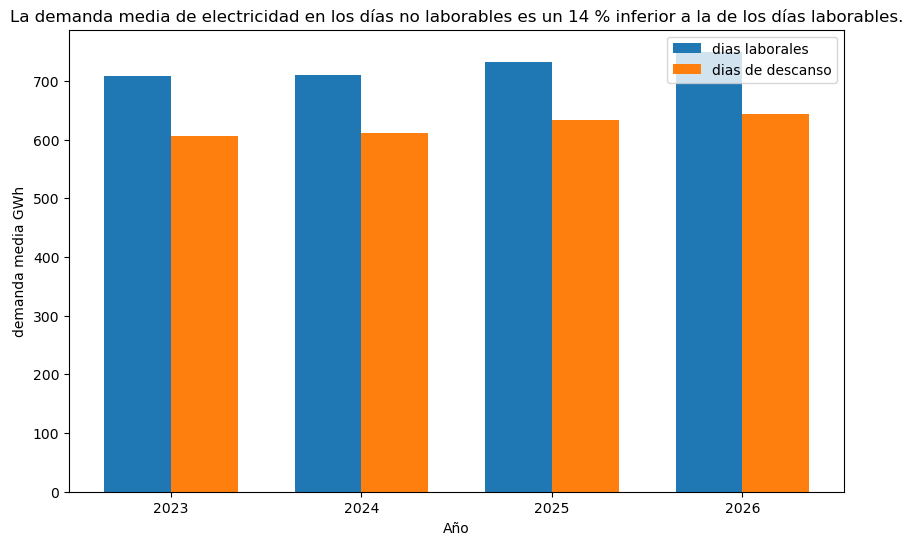

In [20]:
x_pos = np.arange(len(d_media_every_year['año']))
width = 0.35

plt.figure(figsize=(10, 6))

plt.bar(
    x_pos - width/2,
    d_media_every_year['dia_laboral'],
    width,
    label='dias laborales'
)

plt.bar(
    x_pos + width/2,
    d_media_every_year['dia_de_descanso'],
    width,
    label='dias de descanso'
)

plt.xticks(x_pos, d_media_every_year['año'])
plt.xlabel('Año')
plt.ylabel('demanda media GWh')
plt.title(f'La demanda media de electricidad en los días no laborables es un 14 % inferior a la de los días laborables.')

plt.legend()
plt.show()

**A3.** ¿Cuál fue el mes con mayor demanda media de los cuatro años (di el mes y el año)? ¿Y el de menor?

In [21]:
media = round(dias["demanda_gwh"].mean(),2)
tabla_datos = dias.groupby(["año", "mes"])["demanda_gwh"].mean().reset_index(name="demanda media del mes (GWh)")
max_demanda = tabla_datos.loc[tabla_datos["demanda media del mes (GWh)"].idxmax()]
min_demanda = tabla_datos.loc[tabla_datos["demanda media del mes (GWh)"].idxmin()]
resultado3 = pd.DataFrame([max_demanda, min_demanda])
resultado3[["año", "mes"]] = resultado3[["año", "mes"]].astype(int)
resultado3["demanda media del mes (GWh)"] = resultado3["demanda media del mes (GWh)"].round(2)
resultado3.index = ["mayor demanda", "menor demanda"]
resultado3


,año,mes,demanda media del mes (GWh)
mayor demanda,2026,7,814.83
menor demanda,2023,4,610.56


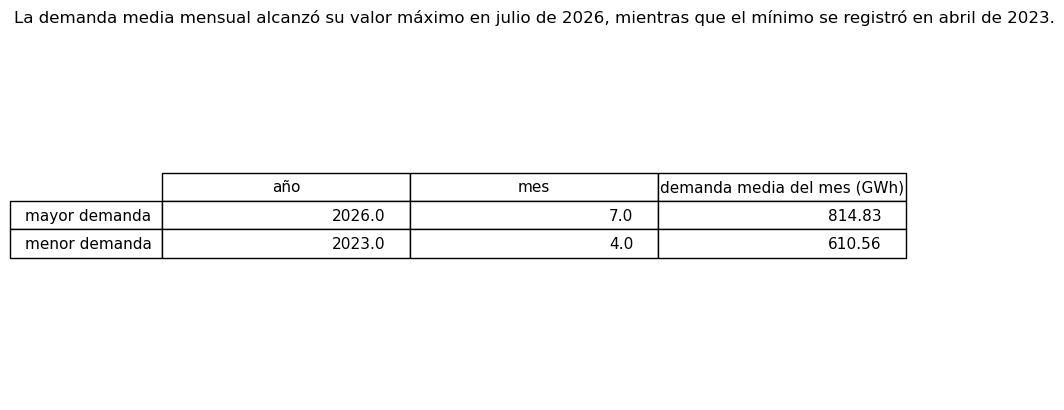

In [22]:
fig, ax = plt.subplots()

ax.axis('off')

table = ax.table(
    cellText=resultado3.values,
    rowLabels=resultado3.index,
    colLabels=resultado3.columns,
    loc='center'
)

table.auto_set_font_size(False)
table.set_fontsize(11)
table.scale(1.5, 1.7)

plt.title('La demanda media mensual alcanzó su valor máximo en julio de 2026, mientras que el mínimo se registró en abril de 2023.')
plt.show()

*Tuve dificultades para convertir los valores de tipo float a integer en las columnas del año y del mes al crear una tabla con pyplot.

# Parte B · SQL

Usa la función `sql("...")` con la base de datos.

**B1.** Saca los cinco días más calurosos (vista `temperatura_nacional`) junto con su demanda. ¿Son también días de mucha demanda? Explica por qué en una o dos frases.

In [23]:
# Tu código aquí
resultado4 = sql("SELECT tn.fecha, tn.t_med, d.demanda_gwh FROM temperatura_nacional tn JOIN demanda d ON tn.fecha = d.fecha  ORDER BY t_med DESC LIMIT 5;")
resultado4

,fecha,t_med,demanda_gwh
0,2025-08-16,31.81,712.442720
1,2025-08-17,31.79,698.786118
2,2023-08-23,31.61,805.114493
3,2025-08-11,31.49,770.154701
4,2025-06-29,31.43,707.452281


In [24]:
demanda_media_total = sql("SELECT AVG(demanda_gwh) AS demanda_media FROM demanda")
demanda_media_total

,demanda_media
0,693.179499


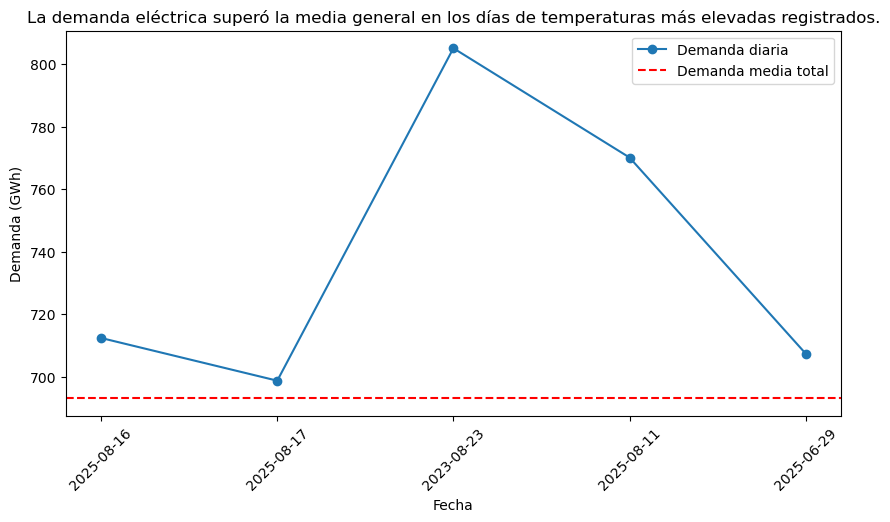

In [25]:
plt.figure(figsize=(10, 5))

# Demanda diaria
plt.plot(
    resultado4['fecha'],
    resultado4['demanda_gwh'],
    marker='o',
    label='Demanda diaria'
)

# Media de demanda total
plt.axhline(
    y=demanda_media_total['demanda_media'].iloc[0],
    color='red',
    linestyle='--',
    label='Demanda media total'
)

plt.xlabel('Fecha')
plt.ylabel('Demanda (GWh)')
plt.title('La demanda eléctrica superó la media general en los días de temperaturas más elevadas registrados.')

plt.xticks(rotation=45)
plt.legend()
plt.show()

Los cinco días con las temperaturas más elevadas se registraron durante el verano. Si comparamos la demanda eléctrica de esos días con la demanda media de todo el periodo analizado, podemos concluir que efectivamente fueron días de mayor consumo, ya que todos los valores superaron la media. Esto podría deberse a una mayor demanda de sistemas de refrigeración debido a las altas temperaturas.

**B2.** Para cada año, calcula la generación solar fotovoltaica en TWh y qué porcentaje supone de toda la generación del año.

In [26]:
resultado5 = sql("SELECT strftime('%Y', fecha) AS año, SUM(gwh) AS ghw_generado_de_sfvt, ROUND(SUM(gwh) *100 / (SELECT SUM(g2.gwh) FROM generacion g2 WHERE strftime('%Y', g2.fecha) = strftime('%Y', generacion.fecha)), 2) AS porsentaje_del_total FROM generacion WHERE tecnologia='Solar fotovoltaica' GROUP BY año")
resultado5

,año,ghw_generado_de_sfvt,porsentaje_del_total
0,2023,37453.799699,14.21
1,2024,44598.990184,16.99
2,2025,50291.508813,18.46
3,2026,55410.233740,22.40


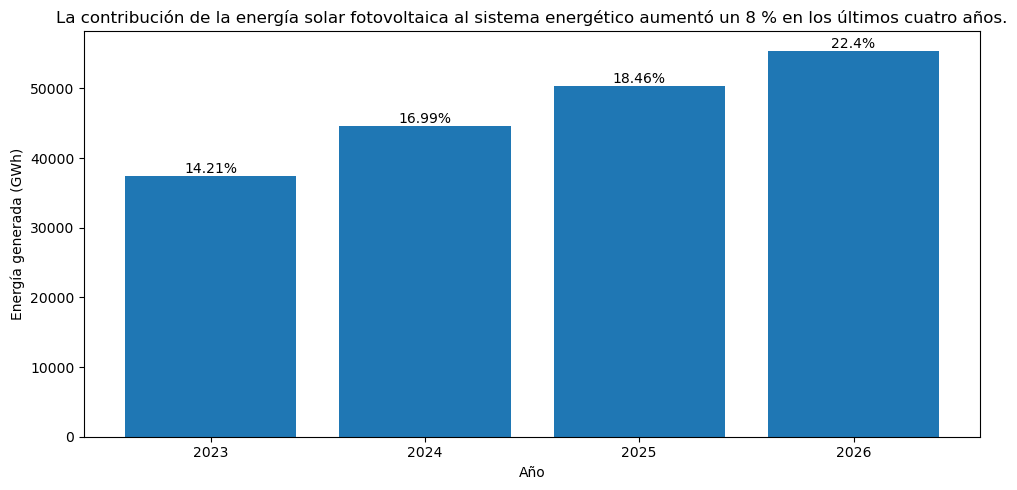

In [27]:
plt.figure(figsize=(10, 5))

bars = plt.bar(resultado5['año'], resultado5['ghw_generado_de_sfvt'])

# Añadir porcentajes encima de las barras
for bar, porcentaje in zip(bars, resultado5['porsentaje_del_total']):
    plt.text(
        bar.get_x() + bar.get_width() / 2,
        bar.get_height(),
        f'{porcentaje}%',
        ha='center',
        va='bottom'
    )

plt.xlabel('Año')
plt.ylabel('Energía generada (GWh)')
plt.title(f'La contribución de la energía solar fotovoltaica al sistema energético aumentó un 8 % en los últimos cuatro años.')

plt.tight_layout()
plt.show()

**B3.** ¿Cuántos días de lluvia (1 mm o más) ha tenido cada ciudad? Ordena de más a menos.

In [28]:
resultado6 = sql("SELECT ciudad, COUNT(fecha) AS dias_de_lluvia FROM tiempo WHERE lluvia_mm >= 1 GROUP BY ciudad ORDER BY dias_de_lluvia DESC")
resultado6

,ciudad,dias_de_lluvia
0,Bilbao,611
1,Barcelona,350
2,Madrid,305
3,Zaragoza,269
4,Sevilla,239
5,Valencia,218


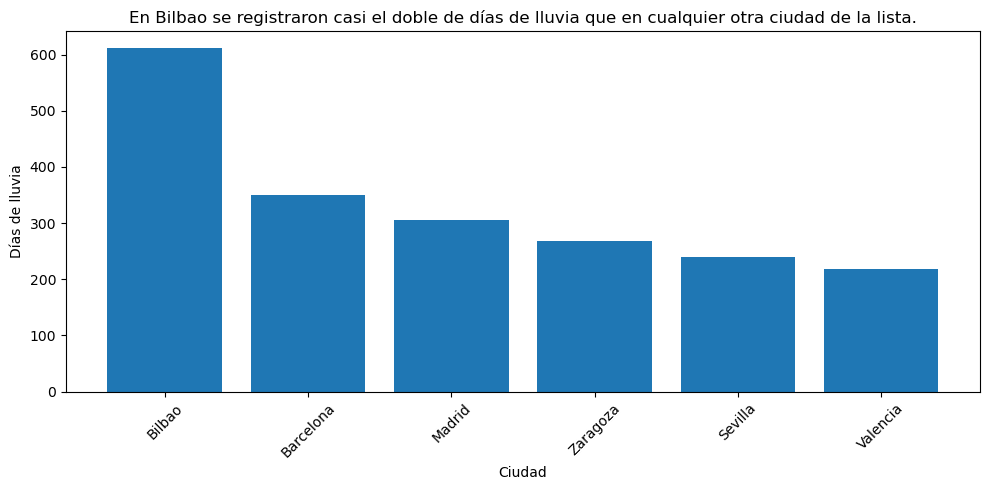

In [29]:
plt.figure(figsize=(10, 5))

plt.bar(resultado6['ciudad'], resultado6['dias_de_lluvia'])

plt.xlabel('Ciudad')
plt.ylabel('Días de lluvia')
plt.title('En Bilbao se registraron casi el doble de días de lluvia que en cualquier otra ciudad de la lista.')

plt.xticks(rotation=45)
plt.tight_layout()

plt.show()

# Parte D · Explica (obligatoria)

Contesta con tus palabras. Frases cortas.

**D1.** Elige una decisión que hayas tenido que tomar en esta prueba y explica por qué la tomaste (4 a 6 líneas).

*Dado que no se ha establecido un objetivo empresarial específico, considero que sería importante centrarse en una visión más general del sistema energético. Mi decisión sería priorizar el desarrollo y la inversión en fuentes de energía renovables. Los datos muestran que la demanda eléctrica puede alcanzar valores elevados, por lo que es importante prepararse para cubrir las necesidades energéticas futuras. El objetivo sería garantizar un suministro eléctrico suficiente y sostenible, reduciendo al mismo tiempo el impacto medioambiental.*

**D2.** Cuenta tu resultado más interesante a alguien que no sabe de datos (3 líneas).

*El resultado más interesante es que en 2026 se registraron más días con una demanda eléctrica superior a 800 GWh que en los tres años anteriores juntos. Esto significa que los días de consumo muy elevado fueron más frecuentes. Este dato podría indicar una mayor presión sobre el sistema eléctrico.*

**D3.** Di un límite de tu análisis, o algo que comprobarías si tuvieras más tiempo.

*Un límite de mi análisis es que no he comprobado si los datos están completos para todos los años. Si tuviera más tiempo, revisaría si tenemos la misma cantidad de registros para cada año y si existen datos que faltan. Esto permitiría asegurar que la comparación entre los años es fiable.*

**D4.** Si has usado una IA, di para qué y cómo comprobaste que el resultado era correcto. Si no la has usado, dilo.

*He utilizado la IA como apoyo durante la prueba. La he consultado cuando no encontraba en la documentación las funciones o bibliotecas adecuadas para realizar determinadas tareas. También la he utilizado para traducir y mejorar la redacción de mis conclusiones en español y para preparar el archivo README a partir del trabajo realizado. He comprobado las soluciones propuestas ejecutando el código y revisando los resultados obtenidos.*